# ASSIGNMENT 6 — Recurrent Neural Network (RNN)
**Họ và tên:** Trần Đình Hiếu  **MSV:** B23DCCE034

## Notebook 00 — Khái niệm, hàm và toán tử để hiểu RNN + Khám phá 2 bộ dữ liệu thời gian

**Nội dung**
1. Vì sao cần RNN cho dữ liệu chuỗi
2. Khái niệm cốt lõi: trạng thái ẩn, chia sẻ tham số, "unroll" theo thời gian
3. Các **hàm** dùng trong RNN (tanh, sigmoid, ReLU, softmax, hàm mất mát) và đạo hàm
4. Các **toán tử** (nhân ma trận, Hadamard, nối vector, cộng, chuyển vị, outer product, clipping)
5. Lan truyền thuận & lan truyền ngược theo thời gian (BPTT)
6. Vanishing / exploding gradient — minh họa số
7. LSTM và GRU
8. Các kiểu kiến trúc RNN
9. Khám phá dữ liệu (EDA): *Service process trong e-commerce* và *Stock*

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
np.random.seed(42); torch.manual_seed(42)
plt.rcParams['figure.dpi'] = 100
os.makedirs('figures', exist_ok=True)

## 1. Vì sao cần RNN?

Mạng nơ-ron truyền thẳng (MLP) coi mỗi đầu vào là độc lập và có kích thước cố định. Dữ liệu **chuỗi** (văn bản, âm thanh, chuỗi thời gian: số đơn hàng mỗi ngày, giá cổ phiếu…) có hai tính chất:

* **Thứ tự quan trọng**: $x_t$ phụ thuộc vào $x_{t-1}, x_{t-2}, \dots$
* **Độ dài thay đổi**: chuỗi có thể dài ngắn khác nhau.

RNN giải quyết bằng cách duy trì một **trạng thái ẩn (hidden state)** $h_t$ — một "bộ nhớ" tóm tắt toàn bộ quá khứ — và cập nhật nó tại mỗi bước thời gian bằng **cùng một bộ tham số**.

## 2. Khái niệm cốt lõi

$$h_t = \tanh\left(W_{xh}\,x_t + W_{hh}\,h_{t-1} + b_h\right), \qquad \hat{y}_t = W_{hy}\,h_t + b_y$$

| Ký hiệu | Ý nghĩa | Kích thước |
|---|---|---|
| $x_t$ | đầu vào tại bước $t$ | $D$ |
| $h_t$ | trạng thái ẩn (bộ nhớ) | $H$ |
| $W_{xh}$ | trọng số input → hidden | $H \times D$ |
| $W_{hh}$ | trọng số hidden → hidden (**hồi quy**) | $H \times H$ |
| $W_{hy}$ | trọng số hidden → output | $O \times H$ |
| $b_h, b_y$ | bias | $H$, $O$ |

* **Chia sẻ tham số (parameter sharing):** $W_{xh}, W_{hh}, W_{hy}$ giống nhau ở mọi bước $t$ → số tham số không phụ thuộc độ dài chuỗi.
* **Unrolling:** "trải" RNN theo thời gian thành một mạng sâu $T$ lớp có chung trọng số:
  `x1 → [h1] → [h2] → … → [hT] → ŷ` (mỗi `[h]` nhận thêm `x_t`).
* **Trạng thái ban đầu** $h_0$ thường là vector 0.
* **Số tham số** của 1 lớp RNN: $H\cdot D + H\cdot H + H$ (+ $O\cdot H + O$ cho lớp đầu ra).

In [2]:
D, H, O = 1, 64, 1
n_rnn = H*D + H*H + H
print('Tham số lớp RNN  :', n_rnn)
print('Tham số lớp Dense:', O*H + O)
# Đối chiếu với PyTorch (PyTorch dùng 2 bias b_ih và b_hh nên nhiều hơn H tham số)
rnn = torch.nn.RNN(D, H)
print('PyTorch nn.RNN   :', sum(p.numel() for p in rnn.parameters()), '(= H*D + H*H + 2H)')

Tham số lớp RNN  : 4224
Tham số lớp Dense: 65
PyTorch nn.RNN   : 4288 (= H*D + H*H + 2H)


## 3. Các hàm (functions) trong RNN

| Hàm | Công thức | Đạo hàm | Vai trò |
|---|---|---|---|
| **tanh** | $\tanh(a)=\frac{e^a-e^{-a}}{e^a+e^{-a}}$, miền $(-1,1)$ | $1-\tanh^2(a)$ | kích hoạt mặc định của trạng thái ẩn; tâm 0 giúp ổn định |
| **sigmoid** $\sigma$ | $\frac{1}{1+e^{-a}}$, miền $(0,1)$ | $\sigma(a)(1-\sigma(a))$ | dùng làm **cổng** (gate) trong LSTM/GRU |
| **ReLU** | $\max(0,a)$ | $\mathbb{1}[a>0]$ | ít dùng cho $h_t$ vì dễ bùng nổ giá trị |
| **softmax** | $\frac{e^{a_i}}{\sum_j e^{a_j}}$ | $s_i(\delta_{ij}-s_j)$ | đầu ra phân loại (dự đoán ký tự/từ tiếp theo) |
| **identity** | $a$ | $1$ | đầu ra hồi quy (dự báo giá trị liên tục — dùng trong bài này) |

**Hàm mất mát**
* Hồi quy: **MSE** $L=\frac1N\sum(\hat{y}-y)^2$, $\;\partial L/\partial\hat y = \frac{2}{N}(\hat y - y)$
* Phân loại: **Cross-entropy** $L=-\sum_i y_i\log \hat{y}_i$; với softmax: $\partial L/\partial a = \hat y - y$
* Với chuỗi many-to-many: $L=\sum_t L_t$.

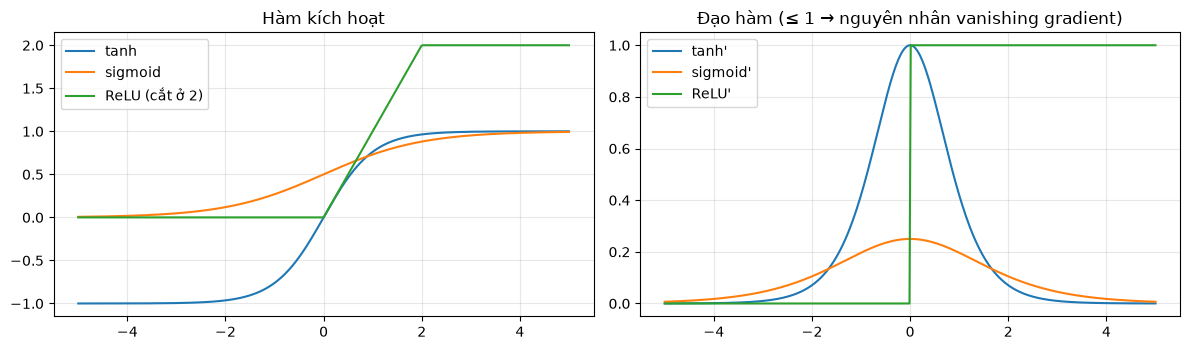

softmax([2, 1, 0.1]) = [0.659 0.242 0.099]


In [3]:
a = np.linspace(-5, 5, 400)
tanh, sig, relu = np.tanh(a), 1/(1+np.exp(-a)), np.maximum(0, a)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(a, tanh, label='tanh'); ax[0].plot(a, sig, label='sigmoid'); ax[0].plot(a, np.clip(relu, 0, 2), label='ReLU (cắt ở 2)')
ax[0].set_title('Hàm kích hoạt'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(a, 1 - tanh**2, label="tanh'"); ax[1].plot(a, sig*(1-sig), label="sigmoid'"); ax[1].plot(a, (a > 0).astype(float), label="ReLU'")
ax[1].set_title('Đạo hàm (≤ 1 → nguyên nhân vanishing gradient)'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures/activations.png', dpi=110); plt.show()

def softmax(z):
    z = z - z.max()          # trừ max để ổn định số học
    e = np.exp(z); return e / e.sum()
print('softmax([2, 1, 0.1]) =', softmax(np.array([2, 1, .1])).round(3))

## 4. Các toán tử (operators)

| Toán tử | Ký hiệu | NumPy / PyTorch | Dùng ở đâu |
|---|---|---|---|
| Nhân ma trận | $W x$ | `W @ x`, `np.dot`, `torch.matmul` | $W_{xh}x_t$, $W_{hh}h_{t-1}$ |
| Nhân từng phần tử (Hadamard) | $a \odot b$ | `a * b` | cổng LSTM/GRU, đạo hàm $\delta\odot(1-h^2)$ |
| Cộng (có broadcasting) | $+$ | `a + b` | cộng bias, cộng hai nhánh |
| Nối vector | $[h_{t-1}; x_t]$ | `np.concatenate`, `torch.cat` | cách viết gọn: $W[h_{t-1};x_t]$ |
| Chuyển vị | $W^\top$ | `W.T` | lan truyền ngược $\delta_{t-1}=W_{hh}^\top\delta_t$ |
| Tích ngoài (outer product) | $\delta\,h^\top$ | `np.outer`, `delta.T @ h` | gradient của trọng số $\partial L/\partial W_{hh}=\sum_t\delta_t h_{t-1}^\top$ |
| Cắt gradient | $g\leftarrow g\cdot\min(1,\frac{c}{\|g\|})$ | `clip_grad_norm_` | chống exploding gradient |

**Lưu ý:** $W_{xh}x_t + W_{hh}h_{t-1} = [W_{xh}\;W_{hh}]\,[x_t;h_{t-1}]$ — hai cách viết tương đương (toán tử nối).

Dưới đây ta tự cài **một bước RNN** bằng NumPy (dùng các toán tử trên) và kiểm tra khớp với `torch.nn.RNNCell`.

In [4]:
cell = torch.nn.RNNCell(input_size=3, hidden_size=4, nonlinearity='tanh')
W_xh, W_hh = cell.weight_ih.detach().numpy(), cell.weight_hh.detach().numpy()
b_h = (cell.bias_ih + cell.bias_hh).detach().numpy()

x_t = np.random.randn(3).astype(np.float32)
h_prev = np.random.randn(4).astype(np.float32)

h_numpy = np.tanh(W_xh @ x_t + W_hh @ h_prev + b_h)                                    # nhân ma trận + cộng
h_concat = np.tanh(np.concatenate([W_xh, W_hh], 1) @ np.concatenate([x_t, h_prev]) + b_h)  # dạng nối vector
h_torch = cell(torch.tensor(x_t)[None], torch.tensor(h_prev)[None])[0].detach().numpy()

print('NumPy  :', h_numpy.round(5))
print('Concat :', h_concat.round(5))
print('PyTorch:', h_torch.round(5))
print('Khớp nhau:', np.allclose(h_numpy, h_torch, atol=1e-6) and np.allclose(h_numpy, h_concat, atol=1e-6))

NumPy  : [ 0.43452 -0.17324  0.8789  -0.47627]
Concat : [ 0.43452 -0.17324  0.8789  -0.47627]
PyTorch: [ 0.43452 -0.17324  0.8789  -0.47627]
Khớp nhau: True


## 5. Lan truyền thuận và lan truyền ngược theo thời gian (BPTT)

**Thuận (many-to-one, dùng trong bài):** với $t = 1..T$: $a_t = W_{xh}x_t + W_{hh}h_{t-1} + b_h$, $h_t=\tanh(a_t)$; đầu ra $\hat y = W_{hy}h_T + b_y$.

**Ngược (Backpropagation Through Time):** đặt $\delta^{h}_T = W_{hy}^\top\,\frac{\partial L}{\partial \hat y}$, rồi lùi $t = T..1$:

$$\delta^{a}_t = \delta^{h}_t \odot (1 - h_t^2)$$
$$\frac{\partial L}{\partial W_{xh}} \mathrel{+}= \delta^{a}_t x_t^\top,\quad \frac{\partial L}{\partial W_{hh}} \mathrel{+}= \delta^{a}_t h_{t-1}^\top,\quad \frac{\partial L}{\partial b_h} \mathrel{+}= \delta^{a}_t$$
$$\delta^{h}_{t-1} = W_{hh}^\top\,\delta^{a}_t$$

Gradient được **cộng dồn qua mọi bước thời gian** vì trọng số được chia sẻ. *Truncated BPTT* chỉ lùi tối đa $k$ bước để giảm chi phí.

## 6. Vanishing / Exploding gradient

$$\frac{\partial h_T}{\partial h_k} = \prod_{t=k+1}^{T} \operatorname{diag}(1-h_t^2)\,W_{hh}$$

* Nếu giá trị kỳ dị lớn nhất của $W_{hh}$ (nhân với đạo hàm tanh ≤ 1) **< 1** → tích co lại theo hàm mũ → **vanishing** (không học được phụ thuộc xa).
* Nếu **> 1** → tích phình ra → **exploding** (loss thành NaN).

Giải pháp: gradient clipping, khởi tạo trực giao (orthogonal) cho $W_{hh}$, chuẩn hóa dữ liệu, dùng **LSTM/GRU**, truncated BPTT.

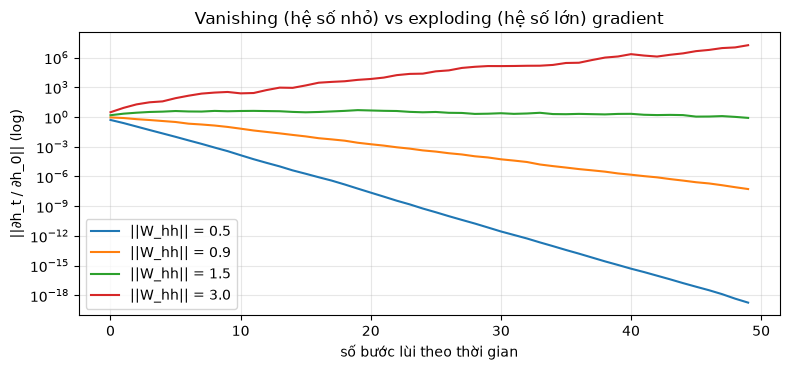

In [5]:
def grad_norm_through_time(scale, T=50, H=32, seed=0):
    rng = np.random.default_rng(seed)
    W = np.linalg.qr(rng.standard_normal((H, H)))[0] * scale     # ma trận trực giao nhân hệ số
    h, J, norms = np.zeros(H), np.eye(H), []
    for t in range(T):
        h = np.tanh(W @ h + rng.standard_normal(H) * 0.5)
        J = np.diag(1 - h**2) @ W @ J                             # Jacobian dh_t/dh_0
        norms.append(np.linalg.norm(J, 2))
    return norms

plt.figure(figsize=(8, 3.8))
for s in [0.5, 0.9, 1.5, 3.0]:
    plt.semilogy(grad_norm_through_time(s), label=f'||W_hh|| = {s}')
plt.xlabel('số bước lùi theo thời gian'); plt.ylabel('||∂h_t / ∂h_0|| (log)')
plt.title('Vanishing (hệ số nhỏ) vs exploding (hệ số lớn) gradient'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figures/vanishing.png', dpi=110); plt.show()

## 7. LSTM và GRU (RNN có cổng)

**LSTM** thêm *cell state* $c_t$ và 3 cổng sigmoid:
$$f_t=\sigma(W_f[h_{t-1};x_t]+b_f),\; i_t=\sigma(W_i[h_{t-1};x_t]+b_i),\; o_t=\sigma(W_o[h_{t-1};x_t]+b_o)$$
$$\tilde c_t=\tanh(W_c[h_{t-1};x_t]+b_c),\quad c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t,\quad h_t=o_t\odot\tanh(c_t)$$
Đường $c_{t-1}\to c_t$ chỉ có phép nhân từng phần tử với $f_t$ và phép cộng → gradient truyền xa mà ít bị triệt tiêu.

**GRU** gọn hơn (2 cổng):
$$z_t=\sigma(W_z[h_{t-1};x_t]),\; r_t=\sigma(W_r[h_{t-1};x_t]),\; \tilde h_t=\tanh(W[r_t\odot h_{t-1};x_t]),\; h_t=(1-z_t)\odot h_{t-1}+z_t\odot\tilde h_t$$

## 8. Các kiểu kiến trúc RNN

| Kiểu | Ví dụ |
|---|---|
| one-to-many | sinh chú thích ảnh |
| **many-to-one** | **dự báo giá trị ngày mai từ $w$ ngày trước (bài này)**, phân loại cảm xúc |
| many-to-many (đồng bộ) | gán nhãn từ loại (POS tagging) |
| many-to-many (seq2seq) | dịch máy, dự báo nhiều bước |

Mở rộng: **stacked RNN** (nhiều lớp chồng nhau), **bidirectional RNN** (đọc hai chiều — không dùng cho dự báo vì nhìn thấy tương lai), **teacher forcing**, **dropout** giữa các lớp.

## 9. Quy trình áp dụng RNN cho chuỗi thời gian
1. Chọn biến mục tiêu và tần suất (ngày).  2. Chia train/test **theo thời gian**.  3. Chuẩn hóa (fit trên train).
4. Cửa sổ trượt → tensor `(batch, time_steps, features)`.  5. Huấn luyện (Adam, MSE, clipping, early stopping).
6. Dự báo, đảo chuẩn hóa, so sánh với baseline naive.

# Phần II — Khám phá hai bộ dữ liệu theo thời gian

### 9.1 Dữ liệu 1 — Service process trong e-commerce (Olist)

Mỗi dòng là một đơn hàng với các mốc của **quy trình phục vụ**: đặt hàng → duyệt thanh toán → giao cho đơn vị vận chuyển → giao tới khách (so với ngày giao dự kiến).

In [6]:
orders = pd.read_csv('olist_orders_dataset.csv', parse_dates=[
    'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date'])
print(orders.shape)
display(orders.head())
display(orders['order_status'].value_counts().to_frame())

(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [7]:
# Thời gian từng công đoạn của quy trình phục vụ (chỉ đơn đã giao)
dl = orders[orders.order_status == 'delivered'].copy()
stages = pd.DataFrame({
    'Duyệt thanh toán (giờ)':     (dl.order_approved_at - dl.order_purchase_timestamp).dt.total_seconds() / 3600,
    'Chờ bàn giao vận chuyển (ngày)': (dl.order_delivered_carrier_date - dl.order_approved_at).dt.total_seconds() / 86400,
    'Vận chuyển tới khách (ngày)':   (dl.order_delivered_customer_date - dl.order_delivered_carrier_date).dt.total_seconds() / 86400,
    'Tổng thời gian giao (ngày)':    (dl.order_delivered_customer_date - dl.order_purchase_timestamp).dt.total_seconds() / 86400,
})
display(stages.describe().T.round(2))
late = (dl.order_delivered_customer_date > dl.order_estimated_delivery_date).mean()
print(f'Tỉ lệ đơn giao trễ so với dự kiến: {late:.1%}')

,count,mean,std,min,25%,50%,75%,max
Duyệt thanh toán (giờ),96464.0,10.28,20.54,0.00,0.22,0.34,14.51,741.44
Chờ bàn giao vận chuyển (ngày),96462.0,2.80,3.54,-171.22,0.87,1.82,3.58,125.76
Vận chuyển tới khách (ngày),96469.0,9.33,8.76,-16.10,4.10,7.10,12.03,205.19
Tổng thời gian giao (ngày),96470.0,12.56,9.55,0.53,6.77,10.22,15.72,209.63


Tỉ lệ đơn giao trễ so với dự kiến: 8.1%


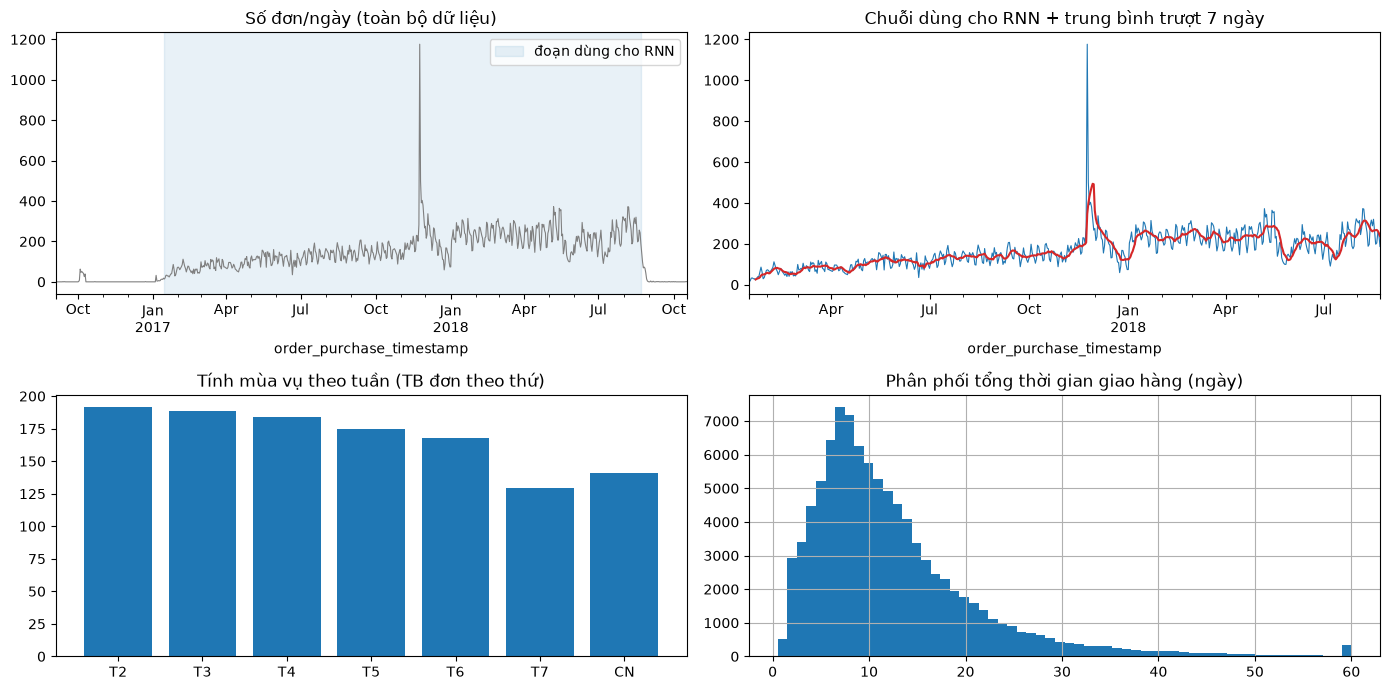

Ngày cao điểm: 2017-11-24 1176 đơn (Black Friday)


In [8]:
daily = orders.set_index('order_purchase_timestamp').resample('D').size()
series = daily['2017-01-15':'2018-08-22']
fig, ax = plt.subplots(2, 2, figsize=(14, 7))
daily.plot(ax=ax[0, 0], color='grey', lw=.8, title='Số đơn/ngày (toàn bộ dữ liệu)')
ax[0, 0].axvspan(pd.Timestamp('2017-01-15'), pd.Timestamp('2018-08-22'), color='tab:blue', alpha=.1, label='đoạn dùng cho RNN'); ax[0, 0].legend()
series.plot(ax=ax[0, 1], lw=.8, title='Chuỗi dùng cho RNN + trung bình trượt 7 ngày')
series.rolling(7).mean().plot(ax=ax[0, 1], color='tab:red')
dow = series.groupby(series.index.dayofweek).mean()
ax[1, 0].bar(['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN'], dow.values); ax[1, 0].set_title('Tính mùa vụ theo tuần (TB đơn theo thứ)')
stages['Tổng thời gian giao (ngày)'].clip(0, 60).hist(bins=60, ax=ax[1, 1]); ax[1, 1].set_title('Phân phối tổng thời gian giao hàng (ngày)')
plt.tight_layout(); plt.savefig('figures/eda_ecommerce.png', dpi=110); plt.show()
print('Ngày cao điểm:', series.idxmax().date(), int(series.max()), 'đơn (Black Friday)')

**Nhận xét:** chuỗi đơn hàng có **xu hướng tăng** trong 2017 rồi ổn định ở 2018, **mùa vụ tuần** (đầu tuần nhiều đơn hơn cuối tuần) và **điểm bất thường** Black Friday (24/11/2017). Hai đầu chuỗi (2016 và sau 22/08/2018) gần như rỗng nên bị loại. Cửa sổ 14 ngày đủ để RNN "thấy" 2 chu kỳ tuần.

### 9.2 Dữ liệu 2 — Stock (chỉ số chứng khoán)

In [9]:
idx = pd.read_csv('indexProcessed.csv', parse_dates=['Date'])
print(idx.shape); display(idx.head())
display(idx.groupby('Index').Date.agg(['min', 'max', 'count']))

(104224, 9)


,Index,Date,Open,High,Low,Close,Adj Close,Volume,CloseUSD
0,HSI,1986-12-31,2568.300049,2568.300049,2568.300049,2568.300049,2568.300049,0.0,333.879006
1,HSI,1987-01-02,2540.100098,2540.100098,2540.100098,2540.100098,2540.100098,0.0,330.213013
2,HSI,1987-01-05,2552.399902,2552.399902,2552.399902,2552.399902,2552.399902,0.0,331.811987
3,HSI,1987-01-06,2583.899902,2583.899902,2583.899902,2583.899902,2583.899902,0.0,335.906987
4,HSI,1987-01-07,2607.100098,2607.100098,2607.100098,2607.100098,2607.100098,0.0,338.923013


,min,max,count
Index,,,
000001.SS,1997-07-02,2021-05-31,5791
399001.SZ,1997-08-22,2021-06-02,5760
GDAXI,1987-12-30,2021-05-31,8438
GSPTSE,1979-06-29,2021-05-31,10526
HSI,1986-12-31,2021-05-31,8492
IXIC,1971-02-05,2021-05-28,12690
J203.JO,2012-02-08,2021-05-31,2346
N100,1999-12-31,2021-06-02,5474
N225,1965-01-05,2021-06-03,13874


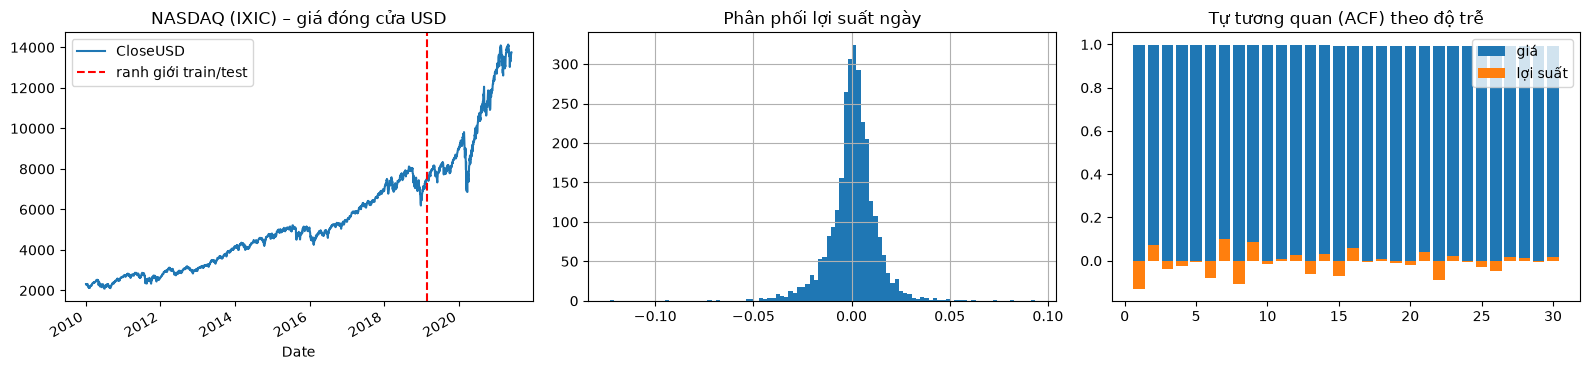

2871 phiên | min=2092 max=14139 | độ lệch chuẩn lợi suất ngày=1.23%


In [10]:
ixic = idx[idx.Index == 'IXIC'].set_index('Date').sort_index().loc['2010-01-01':, 'CloseUSD']
ret = ixic.pct_change().dropna()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ixic.plot(ax=ax[0], title='NASDAQ (IXIC) – giá đóng cửa USD'); ax[0].axvline(ixic.index[int(len(ixic) * .8)], color='red', ls='--', label='ranh giới train/test'); ax[0].legend()
ret.hist(bins=100, ax=ax[1]); ax[1].set_title('Phân phối lợi suất ngày')
lags = range(1, 31)
ax[2].bar(lags, [ixic.autocorr(l) for l in lags], label='giá'); ax[2].bar(lags, [ret.autocorr(l) for l in lags], label='lợi suất')
ax[2].set_title('Tự tương quan (ACF) theo độ trễ'); ax[2].legend()
plt.tight_layout(); plt.savefig('figures/eda_stock.png', dpi=110); plt.show()
print(f'{len(ixic)} phiên | min={ixic.min():.0f} max={ixic.max():.0f} | độ lệch chuẩn lợi suất ngày={ret.std():.2%}')

**Nhận xét:** giá NASDAQ có xu hướng tăng mạnh (không dừng), tự tương quan của **giá** gần 1 ở mọi độ trễ (giá hôm nay ≈ giá hôm qua) trong khi **lợi suất** gần như không tự tương quan → baseline naive rất mạnh với dữ liệu cổ phiếu. Đặc biệt, giá ở tập test (2019–2021) **cao hơn** đỉnh tập train: nếu dùng Min-Max, giá trị test sẽ vượt 1 và RNN (tanh bị chặn) phải ngoại suy. Vì vậy với cổ phiếu ta chuẩn hóa **tương đối theo cửa sổ** (xem bên dưới).

### Tóm tắt thiết lập thí nghiệm (dùng giống nhau ở 3 notebook)

## Dữ liệu & tiền xử lý (dùng chung cho cả 3 thư viện)

| Bộ dữ liệu | Nguồn | Chuỗi thời gian dự báo | Cửa sổ (window) |
|---|---|---|---|
| **E-commerce service process** | `olist_orders_dataset.csv` (Olist, Brazil) | Số đơn hàng được đặt mỗi ngày (15/01/2017 → 22/08/2018) | 14 ngày |
| **Stock** | `indexProcessed.csv` | Giá đóng cửa (USD) chỉ số NASDAQ – `IXIC` (2010 → 05/2021) | 30 phiên |

Các bước:
1. Gom chuỗi theo ngày (đơn hàng) / lọc chỉ số (cổ phiếu).
2. Chia **theo thời gian**: 80% đầu là train, 20% cuối là test (không xáo trộn để tránh rò rỉ thông tin tương lai).
3. Chuẩn hóa — chỉ dùng thống kê của tập train:
   * E-commerce: **Min-Max** về [0, 1].
   * Stock: **chuẩn hóa tương đối** $x'_k = (x_k / x_{t-1} - 1)/s$ (chia cho giá phiên cuối của cửa sổ, $s$ = độ lệch chuẩn lợi suất ngày trên train). Giá NASDAQ giai đoạn test cao hơn hẳn train nên Min-Max sẽ buộc mạng phải *ngoại suy* ngoài [0,1]; cách chuẩn hóa tương đối biến chuỗi thành dừng.
4. Tạo mẫu bằng **cửa sổ trượt**: $X = [x_{t-w}, \dots, x_{t-1}]$ → $y = x_t$ (bài toán *many-to-one*).
5. Đánh giá trên thang giá trị gốc bằng RMSE, MAE, MAPE, $R^2$ và so sánh với **baseline naive** ($\hat{x}_t = x_{t-1}$).

In [11]:
import os, json

DATA_DIR = '.'          # thư mục chứa 2 file CSV
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

def load_ecommerce():
    o = pd.read_csv(f'{DATA_DIR}/olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp'])
    s = o.set_index('order_purchase_timestamp').resample('D').size().astype(float)
    s = s['2017-01-15':'2018-08-22']
    s.name = 'orders_per_day'
    return s

def load_stock(index='IXIC', start='2010-01-01'):
    d = pd.read_csv(f'{DATA_DIR}/indexProcessed.csv', parse_dates=['Date'])
    d = d[d['Index'] == index].set_index('Date').sort_index()
    s = d.loc[start:, 'CloseUSD'].astype(float)
    s.name = f'{index}_close_usd'
    return s

class MinMaxScaler1D:
    def fit(self, x):
        self.min, self.max = float(np.min(x)), float(np.max(x))
        return self
    def transform(self, x):
        return (np.asarray(x) - self.min) / (self.max - self.min)
    def inverse_transform(self, x):
        return np.asarray(x) * (self.max - self.min) + self.min

def prepare(series, window, scaling='minmax', train_ratio=0.8):
    # scaling='minmax'  : x' = (x - min) / (max - min), fit trên train.
    # scaling='relative': x' = (x / x_{t-1} - 1) / s  — chuẩn hóa theo giá cuối cửa sổ (s = độ lệch chuẩn lợi suất train),
    #                     giúp chuỗi không dừng (giá cổ phiếu) trở nên dừng và không phải ngoại suy.
    values = series.values.astype(np.float64)
    n_train = int(len(values) * train_ratio)
    target_idx = np.arange(window, len(values))
    base = values[target_idx - 1]                                   # giá trị ngay trước mục tiêu
    windows = np.stack([values[i - window:i] for i in target_idx])  # (N, T)
    targets = values[target_idx]
    is_train = target_idx < n_train
    if scaling == 'minmax':
        scaler = MinMaxScaler1D().fit(values[:n_train])
        X, y = scaler.transform(windows), scaler.transform(targets)
        inverse = lambda y_s, b: scaler.inverse_transform(y_s)
    else:
        s = float(np.std(targets[is_train] / base[is_train] - 1))
        X, y = (windows / base[:, None] - 1) / s, (targets / base - 1) / s
        inverse = lambda y_s, b: (np.asarray(y_s) * s + 1) * b
    test_base = base[~is_train]
    return dict(name=series.name, series=series, window=window, scaling=scaling,
                X_train=X[is_train][..., None], y_train=y[is_train][:, None],     # (N, T, 1), (N, 1)
                X_test=X[~is_train][..., None], y_test=y[~is_train][:, None],
                dates_test=series.index[target_idx[~is_train]],
                y_test_orig=targets[~is_train],
                naive_test=test_base,                                   # baseline: giá trị hôm trước
                to_original=lambda y_s: inverse(np.ravel(y_s), test_base))

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    err = y_pred - y_true
    mask = y_true != 0
    return dict(RMSE=float(np.sqrt(np.mean(err ** 2))),
                MAE=float(np.mean(np.abs(err))),
                MAPE=float(np.mean(np.abs(err[mask] / y_true[mask])) * 100),
                R2=float(1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)))

DATASETS = {
    'ecommerce': prepare(load_ecommerce(), window=14, scaling='minmax'),
    'stock':     prepare(load_stock('IXIC'), window=30, scaling='relative'),
}
for k, d in DATASETS.items():
    print(f"{k:10s} | series={len(d['series'])} | X_train={d['X_train'].shape} | X_test={d['X_test'].shape}")

ecommerce  | series=585 | X_train=(454, 14, 1) | X_test=(117, 14, 1)
stock      | series=2871 | X_train=(2266, 30, 1) | X_test=(575, 30, 1)


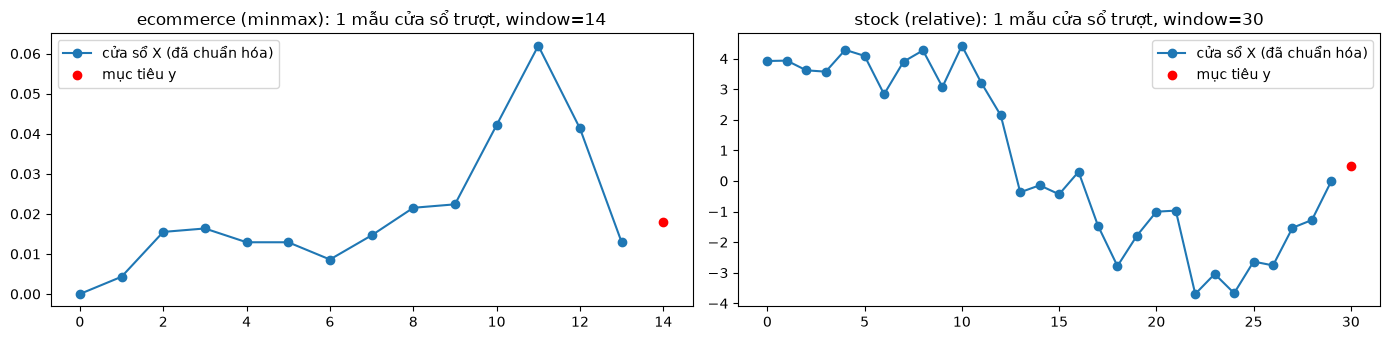

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for a, (k, d) in zip(ax, DATASETS.items()):
    a.plot(d['X_train'][0, :, 0], marker='o', label='cửa sổ X (đã chuẩn hóa)')
    a.scatter([d['window']], d['y_train'][0], color='red', zorder=3, label='mục tiêu y')
    a.set_title(f'{k} ({d["scaling"]}): 1 mẫu cửa sổ trượt, window={d["window"]}'); a.legend()
plt.tight_layout(); plt.show()

**Tiếp theo:**
* `01_RNN_Scratch.ipynb` — cài đặt RNN từ đầu bằng NumPy (forward, BPTT, Adam).
* `02_RNN_Keras.ipynb` — RNN bằng Keras (`SimpleRNN`).
* `03_RNN_PyTorch.ipynb` — RNN bằng PyTorch (`nn.RNN`).